In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import contextily as ctx
pd.set_option('display.float_format', '{:.2f}'.format)
plt.rcParams["font.family"] = "Times New Roman"

# Working on HIES

In [2]:
merged = pd.read_pickle("merged")
merged["Tenure"].unique()

array(['Owner of land and building', 'Free of charge',
       'In exchange for service', 'Rented', 'Other', None, 'Mortgaged',
       'Owner of building only'], dtype=object)

In [3]:
iran_provinces = {
    "آذربایجان شرقی": "East Azerbaijan",
    "آذربایجان غربی": "West Azerbaijan",
    "اردبیل": "Ardabil",
    "اصفهان": "Esfahan",
    "البرز": "Alborz",
    "ایلام": "Ilam",
    "بوشهر": "Bushehr",
    "تهران": "Tehran",
    "خراسان جنوبی": "South Khorasan",
    "خراسان رضوی": "Razavi Khorasan",
    "خراسان شمالی": "North Khorasan",
    "خوزستان": "Khuzestan",
    "زنجان": "Zanjan",
    "سمنان": "Semnan",
    "سیستان و بلوچستان": "Sistan and Baluchestan",
    "فارس": "Fars",
    "قزوین": "Qazvin",
    "قم": "Qom",
    "كردستان": "Kurdistan",
    "كرمان": "Kerman",
    "كهگیلویه و بویراحمد": "Kohgiluyeh and Boyer-Ahmad",
    "لرستان": "Lorestan",
    "مازندران": "Mazandaran",
    "مرکزی": "Markazi",
    "هرمزگان": "Hormozgan",
    "همدان": "Hamadan",
    "چهارمحال و بختیاری": "Chaharmahal and Bakhtiari",
    "کرمانشاه": "Kermanshah",
    "گلستان": "Golestan",
    "گیلان": "Gilan",
    "یزد": "Yazd"
}
merged["province"] = merged["province"].map(iran_provinces)

In [5]:
def weighted_describe(values, weights):
    values = np.asarray(values)
    weights = np.asarray(weights)

    # Drop NaNs
    mask = ~np.isnan(values)
    values = values[mask]
    weights = weights[mask]

    # Weighted count
    count = weights.sum()

    # Weighted mean
    mean = np.average(values, weights=weights)

    # Weighted variance and std
    variance = np.average((values - mean) ** 2, weights=weights)
    std = np.sqrt(variance)

    # Weighted min and max
    min_val = values.min()
    max_val = values.max()

    # Weighted percentiles
    def weighted_percentile(data, weights, percent):
        """Compute weighted percentile (percent between 0-100)."""
        sorter = np.argsort(data)
        data, weights = data[sorter], weights[sorter]
        cdf = np.cumsum(weights) / weights.sum()
        return np.interp(percent / 100, cdf, data)

    q25 = weighted_percentile(values, weights, 25)
    q50 = weighted_percentile(values, weights, 50)  # median
    q75 = weighted_percentile(values, weights, 75)

    return pd.Series({
        "count": round(count,2),
        "mean": round(mean,2),
        "std": round(std,2),
        "min": round(min_val,2),
        "25%": round(q25,2),
        "50%": round(q50,2),
        "75%": round(q75,2),
        "max": round(max_val,2)
    })


In [6]:
data = merged.loc[merged["FoodExp"]!= 0]
data.isna().sum()

HHID                    0
month              150712
household_type          0
region                  0
quarter                 0
                    ...  
OtherExtraSale          0
year                    0
all_expenditure         0
all_energy_EXP          0
energy_Ratio            0
Length: 113, dtype: int64

In [7]:
data["year"] = np.where(
    data["year"] == 1403, 2024, np.where(
        data["year"] == 1402, 2023, np.where(
            data["year"] == 1401, 2022, np.where(
                data["year"] == 1400, 2021, np.where(
                    data["year"] == 99, 2020, np.where(
                        data["year"] == 98, 2019, np.where(
                            data["year"] == 97, 2018, np.where(
                                data["year"] == 96, 2017, np.where(
                                    data["year"] == 95, 2016, np.where(
                                        data["year"] == 94, 2015, np.where(
                                            data["year"] == 93, 2014, np.where(
                                                data["year"] == 92, 2013, np.where(
                                                    data["year"] == 91, 2012, np.where(
                                                        data["year"] == 90, 2011, np.where(
                                                            data["year"] == 89, 2010, pd.NA
                                                        )
                                                    )
                                                )
                                            )
                                        )
                                    )
                                )
                            )
                        )
                    )
                )
            )
        )
    )
)

C:\Users\sinan\AppData\Local\Temp\ipykernel_17944\2401354868.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data["year"] = np.where(


In [8]:
data.columns.to_list()

['HHID',
 'month',
 'household_type',
 'region',
 'quarter',
 'weight',
 'county_code',
 'province_code',
 'province',
 'HHsize',
 'AveAge',
 'NumChild_U5',
 'NumChild_B5_7',
 'NumChild_B7_18',
 'NumChildOver18',
 'HeadWoman',
 'Dep_Student',
 'Num_Literate',
 'NumSpouse',
 'NumEmployed',
 'NumOld',
 'NumMale',
 'NumNotfirstR',
 'Tenure',
 'Room',
 'Area',
 'Skeleton',
 'MainMaterial',
 'PrivateVehicle',
 'Motorcycle',
 'Bike',
 'Radio',
 'Cassette',
 'TVbw',
 'TV',
 'VideoPlayer',
 'Computer',
 'Cellphone',
 'Freezer',
 'Refrigerator',
 'Freez_refrig',
 'Vacuum',
 'Washer',
 'Sewing',
 'Fan',
 'Cooler_water_portable',
 'Cooler_gas_portable',
 'Dishwasher',
 'None',
 'Pipewater',
 'Electricity',
 'Pipegas',
 'Phone',
 'Internet',
 'Bathroom',
 'Kitchen',
 'Cooler_water',
 'Centralcooler',
 'Centralheat',
 'Pakage',
 'Cooler_gas',
 'Sewer_network',
 'Cookfuel',
 'Heatfuel',
 'Hotwaterfuel',
 'FoodExp',
 'CigarExp',
 'NonCatDrinksExp',
 'ClothExp',
 'InvestExp',
 'FurnitureExp',
 'Medica

In [9]:
df = data[['Sewer_network','Pipewater', 'WaterExp']]
for col in df.columns:
    print(f"the name of the col is {col}")
    print(df[col].unique())

the name of the col is Sewer_network
[ 0. 13.  1.]
the name of the col is Pipewater
[1. 0.]
the name of the col is WaterExp
[  35000.       0.   20000. ... 1127000. 1790000. 6520000.]


In [10]:
cols = [
    'Electricity',
    'Pipegas',
    'Phone',
    'Internet',
    'Bathroom',
    'Kitchen',
    'Cooler_water',
    'Centralcooler',
    'Centralheat',
    'Pakage',
    'Cooler_gas',
    'Sewer_network'
]
for col in cols:
    data[col] = np.where(data[col]==0,0,1)
    print(data[col].unique())

[1 0]
[1 0]
[1 0]
[0 1]
[1 0]
[1 0]
[0 1]
[0 1]
[0 1]
[0 1]
[0 1]
[0 1]


C:\Users\sinan\AppData\Local\Temp\ipykernel_17944\2893608805.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col] = np.where(data[col]==0,0,1)


In [11]:
data["Tenure"] = np.where(data["Tenure"].isin(['Owner of land and building', 'Free of charge',
                                               'In exchange for service','Owner of building only']), "Owner",np.where(
                                                  data["Tenure"].isin(['Rented', 'Mortgaged']), "Renter", 'Other'))

C:\Users\sinan\AppData\Local\Temp\ipykernel_17944\2618965913.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data["Tenure"] = np.where(data["Tenure"].isin(['Owner of land and building', 'Free of charge',


In [12]:
cols = [
'PrivateVehicle',
'Motorcycle',
'Bike',
'Radio',
'Cassette',
'TVbw',
'TV',
'VideoPlayer',
'Computer',
'Cellphone',
'Freezer',
'Refrigerator',
'Freez_refrig',
'Vacuum',
'Washer',
'Sewing',
'Fan',
'Cooler_water_portable',
'Cooler_gas_portable',
'Dishwasher',
'None',
'Pipewater',
'Electricity',
'Pipegas',
'Phone',
'Internet',
'Bathroom',
'Kitchen',
'Cooler_water',
'Centralcooler',
'Centralheat',
'Pakage',
'Cooler_gas',
'Sewer_network',
'HeadWoman'
]
for col in cols:
    data[col] = data[col].astype(bool)

C:\Users\sinan\AppData\Local\Temp\ipykernel_17944\1070555551.py:39: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col] = data[col].astype(bool)
C:\Users\sinan\AppData\Local\Temp\ipykernel_17944\1070555551.py:39: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col] = data[col].astype(bool)
C:\Users\sinan\AppData\Local\Temp\ipykernel_17944\1070555551.py:39: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instea

In [13]:
province_to_climate = {
    "Tehran": "BSh",
    "Khuzestan": "BSh",
    "Bushehr": "BSh",
    "Yazd": "BWk",
    "Alborz": "Dsa",
    "Kurdistan": "Dsa",
    "Hamadan": "Dsa",
    "Ardabil": "BSk",
    "East Azerbaijan": "BSk",
    "Zanjan": "BSk",
    "Golestan": "BSk",
    "North Khorasan": "BSk",
    "Razavi Khorasan": "BSk",
    "Gilan": "Cfa",
    "Qom": "BWh",
    "Semnan": "BWh",
    "Esfahan": "BWh",
    "South Khorasan": "BWh",
    "Kerman": "BWh",
    "Hormozgan": "BWh",
    "Sistan and Baluchestan": "BWh",
}

data["climate"] = data["province"].map(province_to_climate).fillna("Csa")

C:\Users\sinan\AppData\Local\Temp\ipykernel_17944\3267722643.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data["climate"] = data["province"].map(province_to_climate).fillna("Csa")


In [14]:
data["GeClimate"] = np.where(data["climate"].isin(['Csa', 'Cfa']), "C", np.where(
    data["climate"].isin(['BSk', 'BSh', 'BWh', 'BWk']), "B", "D"
))
data.groupby(["climate", "GeClimate"]).size()

C:\Users\sinan\AppData\Local\Temp\ipykernel_17944\941048925.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data["GeClimate"] = np.where(data["climate"].isin(['Csa', 'Cfa']), "C", np.where(


climate  GeClimate
BSh      B             65334
BSk      B            118135
BWh      B            130767
BWk      B             18898
Cfa      C             18399
Csa      C            173220
Dsa      D             45576
dtype: int64

In [46]:
#data.to_pickle("data.pkl")
data = pd.read_pickle("data.pkl")


In [47]:
data["water_ratio"] = ((data["WaterExp"] + data['Water_otherExp']) / data["all_expenditure"])*100
data["affordability_problem"] = np.where(data["water_ratio"] > 3, 1, 0)
data["affordability_problem_weighted"] = data["affordability_problem"] * data["weight"]
data["affordability_problem_intensity"] = np.where(data["water_ratio"] > 3, data["water_ratio"] - 3, 0)
data["affordability_problem_intensity_weighted"] = data["affordability_problem_intensity"] * data["weight"]


In [48]:
data2024 = data.loc[(data["year"]==2024)]
data2024.to_pickle("data2024.pkl")

In [5]:
for year in data["year"].unique():
    df = data.loc[(data["year"]==year)]
    hh_all = df["weight"].sum()
    df2 = data.loc[(data["year"]==year)& (data["Sewer_network"]==True)]
    hh_access = df2["weight"].sum()
    por = (hh_access/hh_all) * 100
    print(f"in {year} the proportion of households have access through the sewer network is {round(por,1)}")

in 2010 the proportion of households have access through the sewer network is 19.3
in 2011 the proportion of households have access through the sewer network is 22.4
in 2012 the proportion of households have access through the sewer network is 24.7
in 2013 the proportion of households have access through the sewer network is 26.1
in 2014 the proportion of households have access through the sewer network is 29.1
in 2015 the proportion of households have access through the sewer network is 29.0
in 2016 the proportion of households have access through the sewer network is 31.4
in 2017 the proportion of households have access through the sewer network is 33.3
in 2018 the proportion of households have access through the sewer network is 32.7
in 2019 the proportion of households have access through the sewer network is 34.9
in 2020 the proportion of households have access through the sewer network is 36.2
in 2021 the proportion of households have access through the sewer network is 36.7
in 2

In [11]:
for year in data["year"].unique():
    df = data.loc[(data["year"]==year)&(data["region"]=="Urban")]
    hh_all = df["weight"].sum()
    hh_access = df.loc[df["Sewer_network"]==True]["weight"].sum()
    por = (hh_access/hh_all) * 100
    print(f"in {year} the proportion of households in urban areas have access through the sewer network is {round(por,1)}")

in 2010 the proportion of households in urban areas have access through the sewer network is 25.6
in 2011 the proportion of households in urban areas have access through the sewer network is 30.3
in 2012 the proportion of households in urban areas have access through the sewer network is 32.8
in 2013 the proportion of households in urban areas have access through the sewer network is 35.2
in 2014 the proportion of households in urban areas have access through the sewer network is 39.2
in 2015 the proportion of households in urban areas have access through the sewer network is 38.9
in 2016 the proportion of households in urban areas have access through the sewer network is 41.8
in 2017 the proportion of households in urban areas have access through the sewer network is 43.6
in 2018 the proportion of households in urban areas have access through the sewer network is 42.8
in 2019 the proportion of households in urban areas have access through the sewer network is 45.5
in 2020 the proporti

In [12]:
for year in data["year"].unique():
    df = data.loc[(data["year"]==year)&(data["region"]=="Rural")]
    hh_all = df["weight"].sum()
    hh_access = df.loc[df["Sewer_network"]==True]["weight"].sum()
    por = (hh_access/hh_all) * 100
    print(f"in {year} the proportion of households in rural areas have access through the sewer network is {round(por,1)}")

in 2010 the proportion of households in rural areas have access through the sewer network is 1.6
in 2011 the proportion of households in rural areas have access through the sewer network is 1.3
in 2012 the proportion of households in rural areas have access through the sewer network is 1.5
in 2013 the proportion of households in rural areas have access through the sewer network is 0.8
in 2014 the proportion of households in rural areas have access through the sewer network is 0.8
in 2015 the proportion of households in rural areas have access through the sewer network is 0.8
in 2016 the proportion of households in rural areas have access through the sewer network is 1.3
in 2017 the proportion of households in rural areas have access through the sewer network is 1.1
in 2018 the proportion of households in rural areas have access through the sewer network is 1.0
in 2019 the proportion of households in rural areas have access through the sewer network is 0.9
in 2020 the proportion of hous

In [39]:
for year in data["year"].unique():
    df = data.loc[(data["year"]==year)]
    hh_all = df["weight"].sum()
    df2 = data.loc[(data["year"]==year)& (data["Pipewater"]==True)]
    hh_access = df2["weight"].sum()
    por = (hh_access/hh_all) * 100
    print(f"in {year} the proportion of households have access through the water pipeline is {round(por,1)}")

in 2010 the proportion of households have access through the water pipeline is 97.9
in 2011 the proportion of households have access through the water pipeline is 97.9
in 2012 the proportion of households have access through the water pipeline is 98.5
in 2013 the proportion of households have access through the water pipeline is 97.6
in 2014 the proportion of households have access through the water pipeline is 98.1
in 2015 the proportion of households have access through the water pipeline is 98.5
in 2016 the proportion of households have access through the water pipeline is 98.5
in 2017 the proportion of households have access through the water pipeline is 98.5
in 2018 the proportion of households have access through the water pipeline is 98.2
in 2019 the proportion of households have access through the water pipeline is 98.5
in 2020 the proportion of households have access through the water pipeline is 98.7
in 2021 the proportion of households have access through the water pipeline 

In [14]:
for year in data["year"].unique():
    df = data.loc[(data["year"]==year)&(data["region"]=="Urban")]
    hh_all = df["weight"].sum()
    hh_access = df.loc[df["Pipewater"]==True]["weight"].sum()
    por = (hh_access/hh_all) * 100
    print(f"in {year} the proportion of households in urban areas have access through the water pipeline is {round(por,1)}")

in 2010 the proportion of households in urban areas have access through the water pipeline is 99.6
in 2011 the proportion of households in urban areas have access through the water pipeline is 99.8
in 2012 the proportion of households in urban areas have access through the water pipeline is 99.8
in 2013 the proportion of households in urban areas have access through the water pipeline is 99.4
in 2014 the proportion of households in urban areas have access through the water pipeline is 99.5
in 2015 the proportion of households in urban areas have access through the water pipeline is 99.7
in 2016 the proportion of households in urban areas have access through the water pipeline is 99.7
in 2017 the proportion of households in urban areas have access through the water pipeline is 99.7
in 2018 the proportion of households in urban areas have access through the water pipeline is 99.7
in 2019 the proportion of households in urban areas have access through the water pipeline is 99.6
in 2020 th

In [15]:
for year in data["year"].unique():
    df = data.loc[(data["year"]==year)&(data["region"]=="Rural")]
    hh_all = df["weight"].sum()
    hh_access = df.loc[df["Pipewater"]==True]["weight"].sum()
    por = (hh_access/hh_all) * 100
    print(f"in {year} the proportion of households in rural areas have access through the water pipeline is {round(por,1)}")

in 2010 the proportion of households in rural areas have access through the water pipeline is 93.1
in 2011 the proportion of households in rural areas have access through the water pipeline is 93.0
in 2012 the proportion of households in rural areas have access through the water pipeline is 94.6
in 2013 the proportion of households in rural areas have access through the water pipeline is 92.8
in 2014 the proportion of households in rural areas have access through the water pipeline is 94.3
in 2015 the proportion of households in rural areas have access through the water pipeline is 95.0
in 2016 the proportion of households in rural areas have access through the water pipeline is 95.0
in 2017 the proportion of households in rural areas have access through the water pipeline is 94.6
in 2018 the proportion of households in rural areas have access through the water pipeline is 93.7
in 2019 the proportion of households in rural areas have access through the water pipeline is 94.7
in 2020 th

In [26]:
for year in data["year"].unique():
    df = data.loc[data["year"]==year]
    pop_all = (df["weight"] * df["HHsize"]).sum()
    df2 = df.loc[df["region"]=="Urban"]
    pop_urb = (df2["weight"] * df2["HHsize"]).sum()
    urb = (pop_urb/pop_all) * 100
    print(f"in {year} with the population of {round(pop_all,0)} the urbanization rate is {round(urb,1)}")

in 2010 with the population of 76381960.0 the urbanization rate is 71.4
in 2011 with the population of 79409564.0 the urbanization rate is 70.9
in 2012 with the population of 80256928.0 the urbanization rate is 72.6
in 2013 with the population of 80498319.0 the urbanization rate is 71.9
in 2014 with the population of 82464916.0 the urbanization rate is 72.2
in 2015 with the population of 84649741.0 the urbanization rate is 72.8
in 2016 with the population of 86488780.0 the urbanization rate is 73.0
in 2017 with the population of 86308522.0 the urbanization rate is 74.6
in 2018 with the population of 85636983.0 the urbanization rate is 74.8
in 2019 with the population of 86799571.0 the urbanization rate is 75.2
in 2020 with the population of 87742734.0 the urbanization rate is 75.6
in 2021 with the population of 88245682.0 the urbanization rate is 75.9
in 2022 with the population of 88868658.0 the urbanization rate is 76.5
in 2023 with the population of 88842403.0 the urbanization rate 

In [71]:
df = data.groupby(["province", "Pipewater","region"]).agg(
    province = ("province", "first"),
    region = ("region", "first"),
    #year = ("year", "first"),
    pipewater = ("Pipewater", "first"),
    hh_population = ("weight", "sum"),
).reset_index(drop=True)
df = df.pivot(index = ["province", "region"], columns = "pipewater", values = "hh_population").reset_index()
df.rename(
    columns = {True: "hh_population_with_access", False: "hh_population_without_access"}, inplace = True
)
df.fillna(0, inplace = True)
df["hh_pop"] = df["hh_population_with_access"] + df["hh_population_without_access"]
df["share_access"] = (df["hh_population_with_access"]/df["hh_pop"])*100
df

pipewater,province,region,hh_population_without_access,hh_population_with_access,hh_pop,share_access
0,Alborz,Rural,3217.57,951702.26,954919.83,99.66
1,Alborz,Urban,6810.15,12155660.21,12162470.36,99.94
2,Ardabil,Rural,95689.10,1722163.01,1817852.11,94.74
3,Ardabil,Urban,4305.01,3864250.14,3868555.14,99.89
4,Bushehr,Rural,8171.25,1232328.15,1240499.40,99.34
...,...,...,...,...,...,...
57,West Azerbaijan,Urban,9474.16,9649411.71,9658885.87,99.90
58,Yazd,Rural,12095.44,758522.78,770618.22,98.43
59,Yazd,Urban,1026.61,4530885.43,4531912.04,99.98
60,Zanjan,Rural,103951.68,1508169.86,1612121.54,93.55


In [92]:
df.loc[df["region"]=="Urban", ["province", "share_access"]].sort_values(by = "share_access", ascending = True)

pipewater,province,share_access
15,Gilan,92.74
51,Sistan and Baluchestan,98.67
19,Hamadan,99.39
21,Hormozgan,99.60
33,Kurdistan,99.72
39,Mazandaran,99.75
13,Fars,99.75
5,Bushehr,99.85
17,Golestan,99.87
3,Ardabil,99.89


In [93]:
df.loc[df["region"]=="Rural", ["province", "share_access"]].sort_values(by = "share_access", ascending = True)

pipewater,province,share_access
14,Gilan,77.01
50,Sistan and Baluchestan,77.94
24,Kerman,90.23
52,South Khorasan,91.56
20,Hormozgan,93.34
60,Zanjan,93.55
2,Ardabil,94.74
34,Lorestan,95.35
38,Mazandaran,95.94
26,Kermanshah,96.20


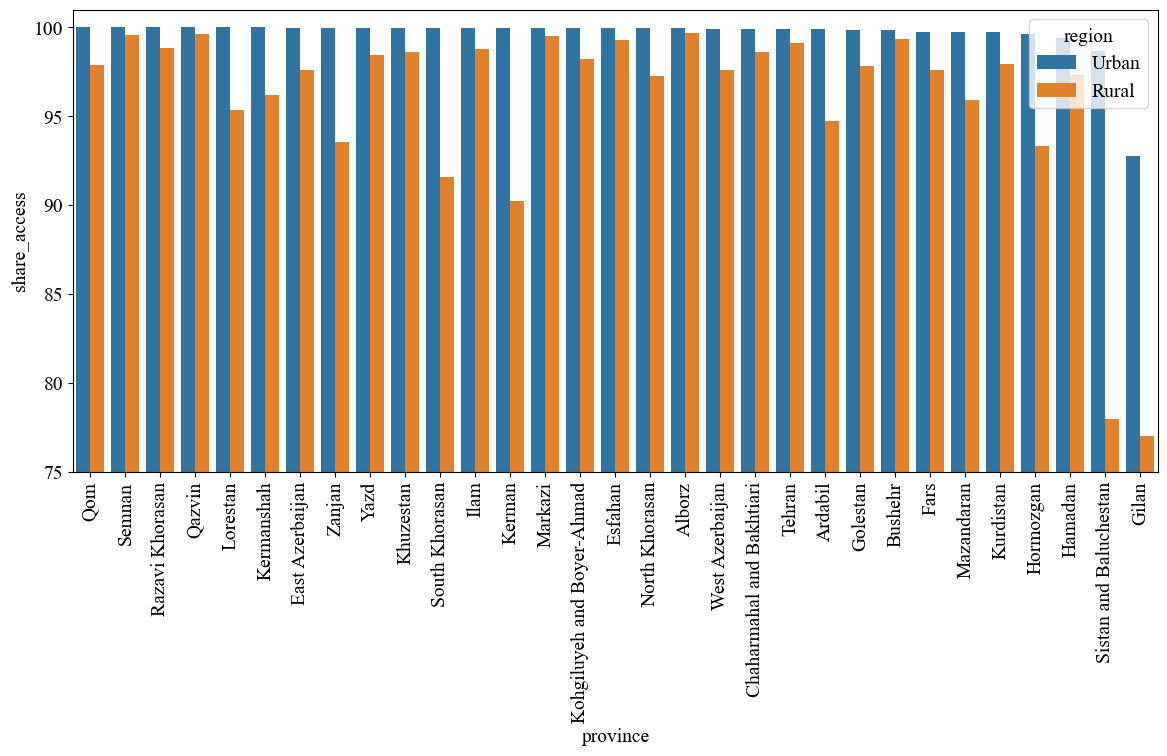

In [89]:
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 14})
ax, fig = plt.subplots(figsize=(14, 6))
sns.barplot(
    data = df.sort_values(by="share_access", ascending=False),
    x= "province",
    y= "share_access",
    hue= "region"
)
plt.xticks(rotation=90)
plt.ylim(75,101)
plt.show()

# Data exploration

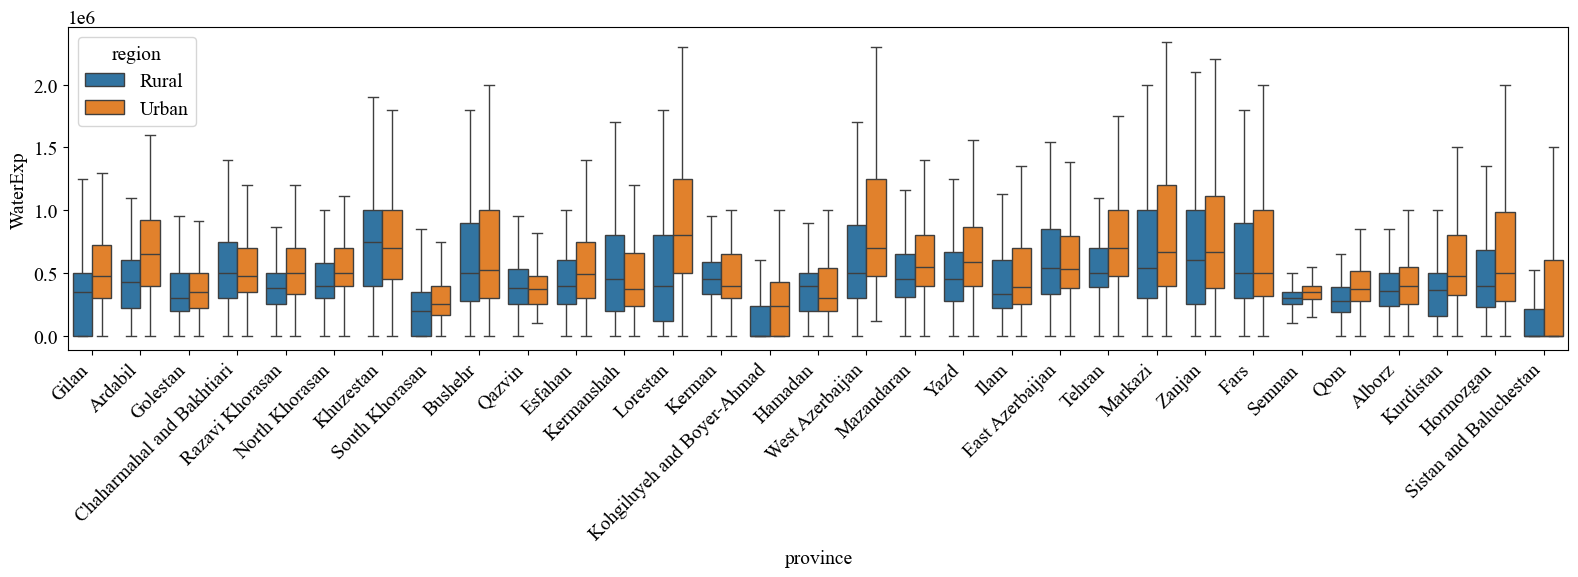

In [95]:
plt.figure(figsize=(16,6))
sns.boxplot(data=data2024, x="province", y="WaterExp", hue="region", showfliers=False)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

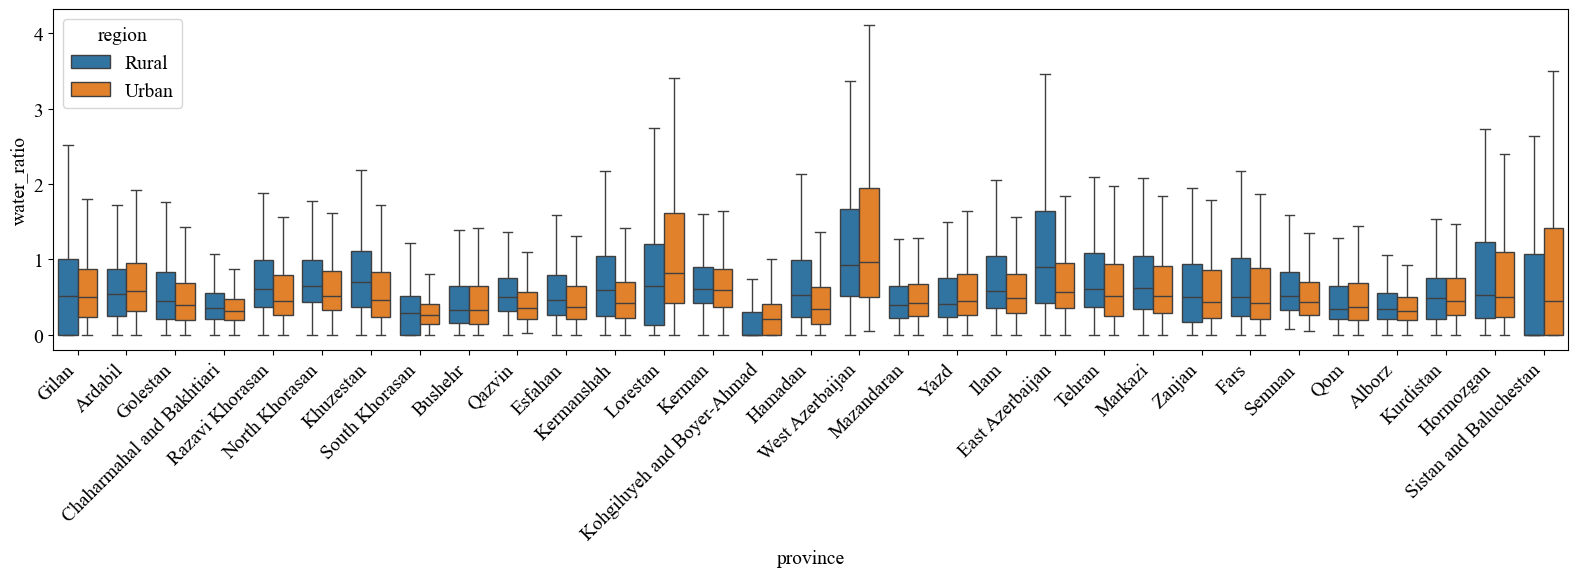

In [94]:
plt.figure(figsize=(16,6))
sns.boxplot(data=data2024, x="province", y="water_ratio", hue="region", showfliers=False)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

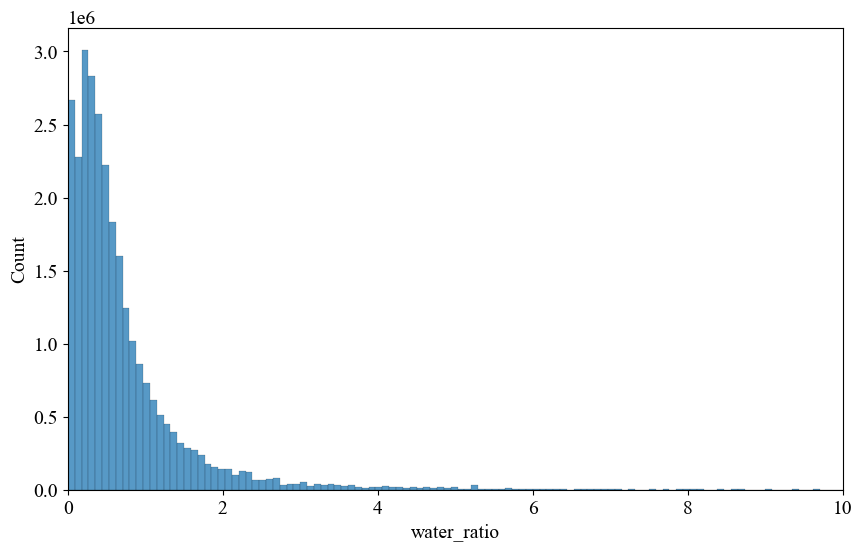

In [16]:
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 14})
plt.figure(figsize=(10, 6))
sns.histplot(
    data=data2024,
    x="water_ratio",
    weights="weight",
    bins=500
)
plt.xlim(0, 10)
plt.show()

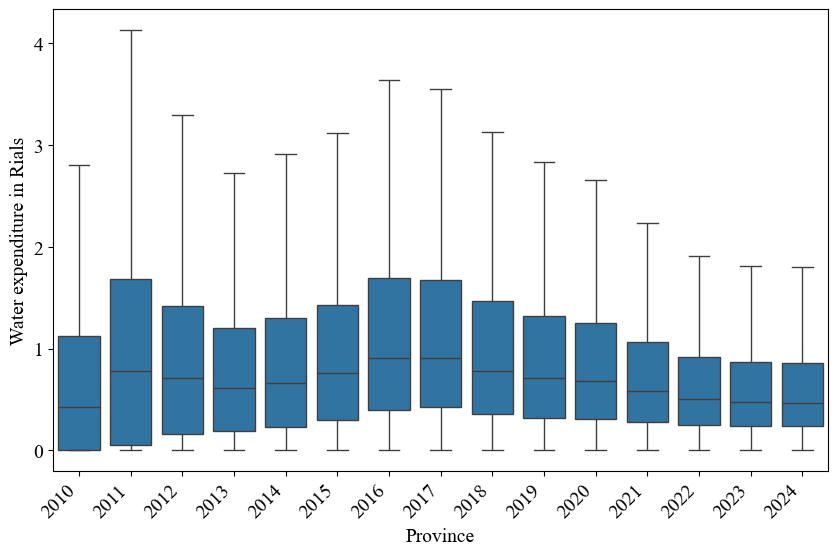

In [18]:
plt.figure(figsize=(10,6))
sns.boxplot(
    data=data,
    y="water_ratio",
    x="year",
    showfliers=False
)


plt.ylabel("Water expenditure in Rials")
plt.xlabel("Province")
plt.xticks(rotation=45, ha='right')

plt.show()

In [113]:
def weighted_median(x, w):
    i = np.argsort(x)
    x, w = np.array(x)[i], np.array(w)[i]
    return x[np.searchsorted(np.cumsum(w), w.sum()/2)]
df = data2024.groupby("Pipewater").apply(
    lambda g: pd.Series({
        "water_ratio_mean": np.average(g["water_ratio"], weights=g["weight"]),
        "water_ratio_median": weighted_median(g["water_ratio"], g["weight"])
    })
).reset_index(drop = False)
print(df)

   Pipewater  water_ratio_mean  water_ratio_median
0      False              0.52                0.00
1       True              0.73                0.47


C:\Users\sinan\AppData\Local\Temp\ipykernel_10952\2774367666.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df = data2024.groupby("Pipewater").apply(


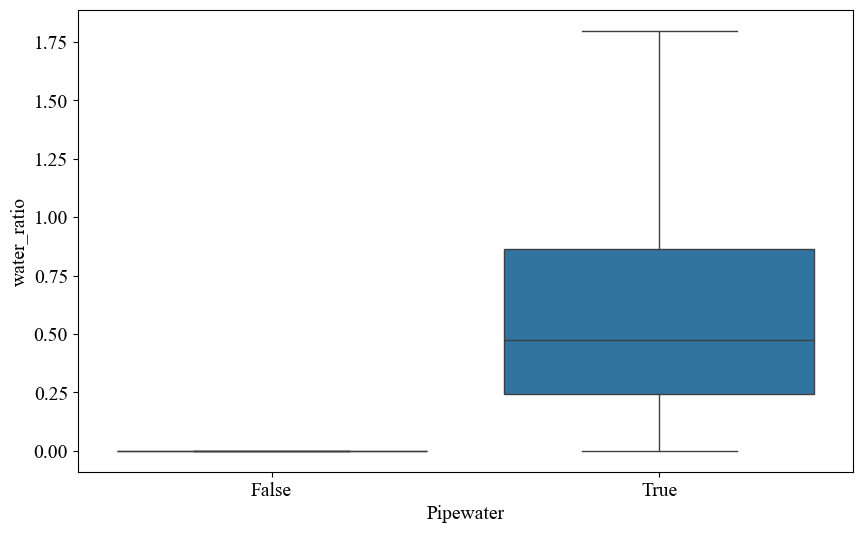

In [111]:
ax, fig = plt.subplots(figsize=(10, 6))
sns.boxplot(
    data=data2024,
    x="Pipewater",
    y="water_ratio",
    showfliers=False
)
plt.show()

In [12]:
income2024 = pd.read_pickle("income1403.pkl")

In [15]:
np.all(income2024["total_income"]/12 == income2024["monthly_income"])

np.True_

In [21]:
income2024.shape

(26475, 3)

In [22]:
data2024.shape

(37343, 118)

In [27]:
data2024.shape[0] - income2024.shape[0]

10868

In [23]:
data2024 = pd.merge(data2024, income2024, how="left", on="HHID")

In [ ]:
data2024["monthly_income"].isna().sum() == data2024.shape[0] - income2024.shape[0]

np.False_

In [31]:
data2024["monthly_income"].isna().sum()

np.int64(10877)

In [32]:
data2024["monthly_income"].notna().sum()

np.int64(26466)

In [34]:
data2024[["HHID", "all_expenditure", "monthly_income"]].head(10)

,HHID,all_expenditure,monthly_income
0,20102398853,6088000.00,NaN
1,22405644553,94132000.00,42500000.00
2,22704667446,165614666.67,41666666.67
3,21406550753,114624128.00,176666666.67
4,20922499847,163495666.67,95833333.33
5,22802679647,59307666.67,63750000.00
6,20608455640,100447833.33,45833333.33
7,22902690940,14663000.00,NaN
8,22705667947,214907000.00,114166666.67
9,20923500241,52390566.67,66666666.67


Some of the samples included in the 37343 observations had already been excluded from the income calculation, primarily due to invalid income values (9)
Some of the samples included in the 26475 observations had already been excluded from the expenditure calculation, primarily due to 0 food expenditures (9)

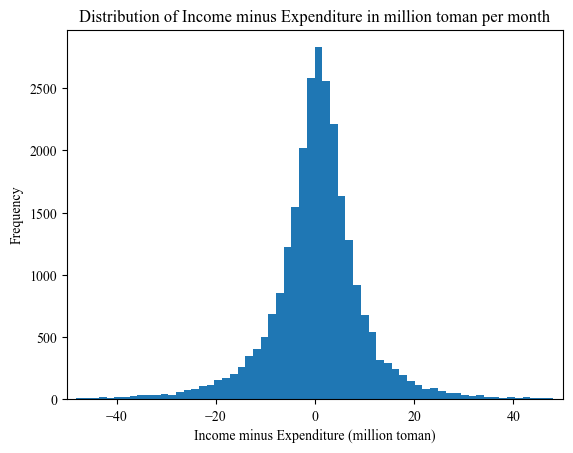

In [35]:
data2024["income_expenditure"] = (data2024["monthly_income"]-data2024["all_expenditure"])/10000000
plt.hist(data2024["income_expenditure"], bins=1000)
plt.title("Distribution of Income minus Expenditure in million toman per month")
plt.xlabel("Income minus Expenditure (million toman)")
plt.xlim(-50, 50)
plt.ylabel("Frequency")
plt.show()

In [36]:
data2024.to_pickle("data2024.pkl")

In [37]:
data2024.groupby("region").size()

region
Rural    18069
Urban    19274
dtype: int64

In [38]:
19274/37343

0.5161342152478376

In [16]:
data2024[["HHID","province","Pipewater","WaterExp","Water_otherExp","all_expenditure","water_ratio",'affordability_problem','affordability_problem_weighted','affordability_problem_intensity',
 'affordability_problem_intensity_weighted']]

,HHID,province,Pipewater,WaterExp,Water_otherExp,all_expenditure,water_ratio,affordability_problem,affordability_problem_weighted,affordability_problem_intensity,affordability_problem_intensity_weighted
545038,20102398853,Gilan,True,0.00,0.00,6088000.00,0.00,0,0.00,0.00,0.00
545039,22405644553,Ardabil,True,400000.00,0.00,94132000.00,0.42,0,0.00,0.00,0.00
545040,22704667446,Golestan,True,85000.00,0.00,165614666.67,0.05,0,0.00,0.00,0.00
545041,21406550753,Chaharmahal and Bakhtiari,True,0.00,0.00,114624128.00,0.00,0,0.00,0.00,0.00
545042,20922499847,Razavi Khorasan,True,800000.00,0.00,163495666.67,0.49,0,0.00,0.00,0.00
...,...,...,...,...,...,...,...,...,...,...,...
582538,12707337550,Golestan,True,450000.00,0.00,294639964.25,0.15,0,0.00,0.00,0.00
582539,11403177747,Chaharmahal and Bakhtiari,True,420000.00,0.00,133760833.33,0.31,0,0.00,0.00,0.00
582540,12713343553,Golestan,True,250000.00,0.00,58716333.33,0.43,0,0.00,0.00,0.00
582541,12105246550,Yazd,True,640000.00,0.00,175853333.33,0.36,0,0.00,0.00,0.00


In [5]:
water2024 = data2024.loc[data2024["Pipewater"]==True]
water2024 = water2024.groupby("province").agg(
    province = ("province", "first"),
    Nj = ("weight", "sum"),
    Nj_sample = ("HHID", "count"),
    Tj = ("affordability_problem_weighted", "sum"),
    Tj_sample = ("affordability_problem", "sum"),
    I = ("affordability_problem_intensity_weighted", "sum"),
    I_sample = ("affordability_problem_intensity", "sum")
). reset_index(drop=True)
water2024

,province,Nj,Nj_sample,Tj,Tj_sample,I,I_sample
0,Alborz,1009993.00,871,7181.00,6,4728.56,6.57
1,Ardabil,417990.00,1040,8724.00,20,10885.08,26.04
2,Bushehr,431942.00,1112,8974.00,18,27434.42,64.15
3,Chaharmahal and Bakhtiari,314439.00,1145,1471.00,5,2854.63,9.05
4,East Azerbaijan,1374712.00,1256,52552.00,75,139956.74,211.83
5,Esfahan,1817402.00,1217,28305.00,25,28208.20,44.56
6,Fars,1652010.00,1448,57939.00,52,135474.34,140.24
7,Gilan,833603.00,1107,28363.00,31,77763.96,88.40
8,Golestan,650345.00,1659,6184.00,18,5608.33,17.82
9,Hamadan,566827.00,1261,9583.00,27,14153.75,42.29


In [6]:
water2024["PAP"] = round((water2024["Tj"]/ water2024["Nj"])*100, 2)
water2024["API"] = round((water2024["I"]/ water2024["Tj"]), 2)
water2024

,province,Nj,Nj_sample,Tj,Tj_sample,I,I_sample,PAP,API
0,Alborz,1009993.00,871,7181.00,6,4728.56,6.57,0.71,0.66
1,Ardabil,417990.00,1040,8724.00,20,10885.08,26.04,2.09,1.25
2,Bushehr,431942.00,1112,8974.00,18,27434.42,64.15,2.08,3.06
3,Chaharmahal and Bakhtiari,314439.00,1145,1471.00,5,2854.63,9.05,0.47,1.94
4,East Azerbaijan,1374712.00,1256,52552.00,75,139956.74,211.83,3.82,2.66
5,Esfahan,1817402.00,1217,28305.00,25,28208.20,44.56,1.56,1.00
6,Fars,1652010.00,1448,57939.00,52,135474.34,140.24,3.51,2.34
7,Gilan,833603.00,1107,28363.00,31,77763.96,88.40,3.40,2.74
8,Golestan,650345.00,1659,6184.00,18,5608.33,17.82,0.95,0.91
9,Hamadan,566827.00,1261,9583.00,27,14153.75,42.29,1.69,1.48


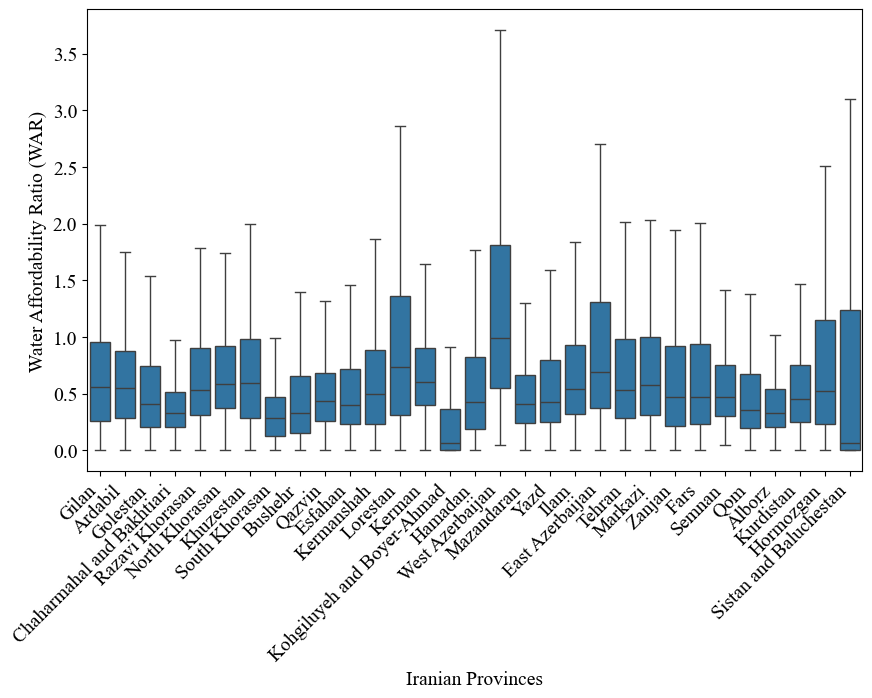

In [34]:
df = data2024.loc[(data2024["Pipewater"]==True)]
ax, fig = plt.subplots(figsize=(10, 6))
sns.boxplot(
    data = df,
    x = "province",
    y = "water_ratio",
    showfliers=False
)
plt.ylabel("Water Affordability Ratio (WAR)")
plt.xlabel("Iranian Provinces")
plt.xticks(rotation=45, ha='right')
plt.show()

In [49]:
df = data2024.loc[(data2024["Pipewater"]==True)]
df.groupby("province")["water_ratio"].describe()

,count,mean,std,min,25%,50%,75%,max
province,,,,,,,,
Alborz,871.00,0.45,0.48,0.00,0.21,0.33,0.54,5.78
Ardabil,1040.00,0.71,0.75,0.00,0.29,0.55,0.88,10.65
Bushehr,1112.00,0.59,1.06,0.00,0.15,0.33,0.65,17.75
Chaharmahal and Bakhtiari,1145.00,0.42,0.42,0.00,0.20,0.33,0.51,5.58
East Azerbaijan,1256.00,1.13,1.55,0.00,0.38,0.69,1.31,17.13
Esfahan,1217.00,0.62,0.86,0.00,0.23,0.41,0.72,15.15
Fars,1448.00,0.82,1.45,0.00,0.24,0.47,0.94,36.59
Gilan,1107.00,0.81,1.39,0.00,0.26,0.56,0.96,33.53
Golestan,1659.00,0.56,0.60,0.00,0.21,0.41,0.74,6.74


In [50]:
df = data2024.loc[(data2024["Pipewater"]==True)]
np.average(df["water_ratio"], weights=df["weight"])

np.float64(0.7314860144549625)

In [ ]:
data101[,water_ratio:= ((water_cost+water_related_cost+wastewater_cost+wastewater_related_cost)/Total_Expenditure_Month)*100]
data101[,affordability_problem:= ifelse(water_ratio>3,1,0)]
data101[,affordability_problem_intensity:= ifelse(water_ratio>3, water_ratio-3,0)]
summary(data101$affordability_problem_intensity)

water_ap<- data101[affordability_problem==1, .(
  Tj= round(sum(weight), digits = 0),
  intens= sum(affordability_problem_intensity*weight)
  ), by = province]
water_ap<- full_join(water_ap, ostan_pop, by = "province")
water_ap<- as.data.table(water_ap)
water_ap[, ratio_province_ap:= (Tj/province_hh)*100]
water_ap[, intensity_ap:= (intens/Tj)]
water_ap<- merge(water_ap, province_main_TableToExcel, by = "province")

ggplot(data = data101, mapping = aes(x= Province_N, y= water_ratio))+
  geom_boxplot() +
  ylim(0,5) +
  ylab("WAR(%)")+
  xlab("استان")+
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

v = sum(water_ap$intens, na.rm = TRUE)/ sum(water_ap$Tj, na.rm = TRUE)
x = (sum(water_ap$Tj, na.rm = TRUE)/ sum(water_ap$province_hh))*100
ggplot(data = water_ap, mapping = aes(x= intensity_ap, y= ratio_province_ap))+
  geom_point() +
  geom_text(aes(label = Province_N), vjust = -0.5,hjust = 0.5 , size = 3)+
  ylab("Prevalence of Affordability Problem (%)")+
  xlab("Intensity of Affordability Problem")+
  geom_hline(yintercept= x)+
  geom_vline(xintercept = v)